# Explainable Machine Learning for Basel and IFRS 9 Credit Risk
### A Placebo-Controlled Test of Narrative Features — companion notebook

**The problem in one sentence.** A credit model can look smarter simply because a new feature tells it *when a loan was made*: any series that changes only over time (such as the tone of central-bank statements) works as a clock for the origination period, so the usual evidence — a gain in AUC, or a high rank in an importance report — can mislead (a vintage problem: Breeden 2007; Forster and Sudjianto 2013).

**The gap.** To our knowledge no accepted test separates real information from this timing effect (the supervisory-narrative studies, e.g. Gorin, Gosky and Suher 2023; Bholat et al. 2017, show narrative is plausibly relevant but do not test it against placebos).

**The protocol this notebook runs.** A placebo-controlled test: compare the real feature with random series built to mimic it (shuffled, random-walk and autocorrelated placebos), control for the origination period, and test at the level of each central-bank statement.

**The evidence.** Tone is the worked example, on peer-to-peer data (Lending Club with FOMC statements; Bondora with ECB statements). The naive gains are reproduced by placebos. Once the period is controlled, no tone effect is detectable at this design's low power. **This is not a finding that tone does not matter** — narrative is plausible but untested on bank credit.

**Next step.** The same protocol on loan-level supervisory data for corporate and small and medium-sized enterprise credit (see the proposal).

**What the notebook does, in one paragraph.** We first build a standard probability-of-default (PD) model
(Part 1). Then we build a "tone index" from central-bank statements (Part 2) and ask whether adding that
tone to a PD model helps (Part 3). The answer looks like *yes* — until we repeat the test with a **fake tone
series** (the real tone shuffled across dates, a *placebo*). The fake tone helps just as much, because any
series that depends only on time lets the model recognise *when* a loan was made. Parts 4 and 5 show how to
test properly (control for the origination period; compare importance against placebos). Part 6 measures how
often the *standard* check is passed by 180 meaningless series.

**Order of the notebook (matches the paper)**

| Part | Question it answers | Paper section |
|---|---|---|
| 1 | What does a normal, explainable PD model look like? (baseline) | 4.1 |
| 2 | How is the tone index built from ECB / FOMC statements? | 4.2 |
| 3 | Does tone seem to help? Does a *fake* tone help just as much? | 5 (Tables 9–11) |
| 4 | Does tone still matter once the origination period is controlled? | 5 (Table 12) |
| 5 | Does a feature-importance report tell a real driver from a clock? | 5 (Table 13) |
| 6 | How often does the standard check pass a *meaningless* series? (pass-rate experiment) | 5.10 (Table 14, Figure 7) |
| Appendix | How the raw data were downloaded (run once, needs internet) | – |

**How to use it.** Run the cells from top to bottom. Change only the *Settings* cell. Every code cell has a
short note above it saying **what** we do, **why**, and **how** in plain words.

> **Honest status notes**
> * The data-cleaning cell in Part 1 was **reconstructed** from the written cleaning plan (the original cleaning code was not in the notebook that was uploaded). Check that the AUC it produces matches the paper (0.855 logistic, 0.860 gradient boosting).
> * The tone numbers in the paper use the **hand-built Loughran–McDonald-style word list** (`lm_lexicon.py`). The *official* list (`pysentiment2`) can be selected with `SCORING = "official"`; if you switch, results may change and the paper tables must be re-checked.
> * The optional SHAP cell (end of Part 1) needs the `shap` package and has not been run by the author of this notebook.

**What:** set every file path and run-size option in one place.
**Why:** so that nothing else in the notebook has to be edited; a reader sees the whole set-up at a glance.
**How:** change `DATA_DIR` to the folder where your files live. The three "size" options trade speed for precision: the paper used `N_PLACEBOS = 10`, `N_PERM = 5000`, `N_BOOT = 1000`, `PASS_K = 60`, `PASS_BOOT = 200`. For a quick practice run lower them (e.g. 3, 500, 200).

In [103]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# ---- 1. Where are your files? (change only this line) ----
DATA_DIR = Path("data")   # put the raw data files in a folder called "data" next to this notebook

GMSC_CSV     = DATA_DIR / "cs-training.csv"        # Give Me Some Credit (Kaggle)
LC_CSV       = DATA_DIR / "loan.csv"               # Lending Club loans, 2007-2015 export
BONDORA_CSV  = DATA_DIR / "LoanData.csv"           # Bondora loans (Kaggle: marcobeyer/bondora-loans)
ECB_DIR      = DATA_DIR / "ecb_statements_all"     # one text file per ECB statement: ecb_YYYY-MM-DD.txt
FOMC_DIR     = DATA_DIR / "fomc_statements"        # one text file per FOMC statement: fomc_YYYY-MM-DD.txt
ECB_TONE_CSV  = DATA_DIR / "ecb_sentiment_scores_2009_2026.csv"
FOMC_TONE_CSV = DATA_DIR / "fomc_sentiment_scores.csv"

# ---- 2. Which word list scores the tone? ----
# "handbuilt" = the list used for ALL numbers in the paper (needs lm_lexicon.py next to this notebook)
# "official"  = the published Loughran-McDonald list via pysentiment2 (pip install pysentiment2)
SCORING = "handbuilt"

# ---- 3. Run size (paper values in brackets) ----
N_PLACEBOS = 10      # number of shuffled-tone placebos          [10]
N_PERM     = 5000    # permutations in the statement-level test  [5000]
N_BOOT     = 1000    # bootstrap resamples for the AUC-gain CI   [1000]
LC_MAX_ROWS = 400_000   # cap on Lending Club rows in Part 4      [400000; the file has fewer]
PASS_K     = 3       # Part 6: placebo series of EACH of 3 types per dataset and control  [60]
PASS_BOOT  = 200     # Part 6: bootstrap resamples per placebo   [200]

# ---- 4. Fixed choices used throughout ----
SEED = 42
OOT_CUT_LC      = "2014-01-01"   # Lending Club: train before this date, test on/after
OOT_CUT_BONDORA = "2021-01-01"   # Bondora: same idea

**What:** load the Python tools used everywhere.
**Why:** one import cell keeps the later cells short. Nothing here changes any data.
**How:** `pandas` = tables, `numpy` = maths, `sklearn` = models and scores, `matplotlib/seaborn` = charts.

In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

sns.set_style("whitegrid")
pd.set_option("display.width", 160)

---
# Part 1 — Baseline PD model (Give Me Some Credit)
*Goal of this part: show a standard, explainable PD model that a bank could defend — and obtain the reference numbers (AUC, KS, calibration) that the later tests are compared against.*

**What:** load the raw credit data and look at it.
**Why:** before cleaning anything we must see its size, the share of defaulters, and which columns have missing values.
**How:** `read_csv` loads the file; `value_counts` gives the default share; `isnull().sum()` counts missing cells.

In [105]:
df = pd.read_csv(GMSC_CSV, encoding="latin1")
print("Shape:", df.shape)
print("\nDefault share (SeriousDlqin2yrs = 1):")
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))
print("\nMissing values per column:")
print(df.isnull().sum())

Shape: (150000, 12)

Default share (SeriousDlqin2yrs = 1):
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64

Missing values per column:
Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


**What:** check the three known data problems — placeholder codes (96/98) in the delinquency counts, impossible values (age 0, huge ratios), and whether the broken debt ratios come from missing income.
**Why:** a bank validation team expects every cleaning rule to be backed by evidence, not by habit.
**How:** count rows that break each rule; compare how often income is missing among absurd vs normal debt ratios.

In [106]:
if "Unnamed: 0" in df.columns:          # stray row-number column in the Kaggle file
    df = df.drop(columns=["Unnamed: 0"])

delinq_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
               "NumberOfTime60-89DaysPastDueNotWorse",
               "NumberOfTimes90DaysLate"]

for col in delinq_cols:
    print(f"{col}: {(df[col] >= 96).sum()} rows with value >= 96 (placeholder error codes, not real counts)")

print("\nRows with age == 0:", (df["age"] == 0).sum())
print("\nDebtRatio percentiles:\n", df["DebtRatio"].quantile([0.95, 0.99, 0.995, 0.999, 1.0]))
print("\nUtilisation percentiles:\n", df["RevolvingUtilizationOfUnsecuredLines"].quantile([0.95, 0.99, 0.995, 0.999, 1.0]))

absurd_ratio = df["DebtRatio"] > 10
no_income = df["MonthlyIncome"].isnull()
print(f"\nDebtRatio > 10 : {absurd_ratio.sum()} rows, income missing in {no_income[absurd_ratio].mean():.1%} of them")
print(f"DebtRatio <= 10: {(~absurd_ratio).sum()} rows, income missing in {no_income[~absurd_ratio].mean():.1%} of them")

NumberOfTime30-59DaysPastDueNotWorse: 269 rows with value >= 96 (placeholder error codes, not real counts)
NumberOfTime60-89DaysPastDueNotWorse: 269 rows with value >= 96 (placeholder error codes, not real counts)
NumberOfTimes90DaysLate: 269 rows with value >= 96 (placeholder error codes, not real counts)

Rows with age == 0: 1

DebtRatio percentiles:
 0.950      2449.000
0.990      4979.040
0.995      6186.010
0.999     10613.074
1.000    329664.000
Name: DebtRatio, dtype: float64

Utilisation percentiles:
 0.950        1.000000
0.990        1.092956
0.995        1.366269
0.999     1571.006000
1.000    50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

DebtRatio > 10 : 28877 rows, income missing in 92.7% of them
DebtRatio <= 10: 121123 rows, income missing in 2.4% of them


**What:** clean the data following the written plan. **(This cell was reconstructed — see the status note at the top.)**
**Why:** each rule removes a data error without deleting borrowers; missing income is *flagged* first because "no income reported" can itself signal risk.

| Problem | Treatment |
|---|---|
| age = 0 (1 row) | replace with median age |
| MonthlyIncome missing (about 20 %) | add flag `Income_Missing`, then fill with the median |
| NumberOfDependents missing | add flag `Dependents_Missing`, then fill with the median |
| DebtRatio absurd (> 10) | cap at 10 |
| Utilisation absurd | cap at 2 (twice the limit is already maximum stress) |
| Delinquency codes 96/98 | replace with the median (almost certainly 0) |

**How:** medians are taken from the valid values only, so the error codes cannot distort them.

In [107]:
clean = df.copy()

# 1. Missing-value flags are created BEFORE filling, so the information is not lost
clean["Income_Missing"]     = clean["MonthlyIncome"].isnull().astype(int)
clean["Dependents_Missing"] = clean["NumberOfDependents"].isnull().astype(int)

# 2. Impossible age
valid_age_median = clean.loc[clean["age"] > 0, "age"].median()
clean.loc[clean["age"] == 0, "age"] = valid_age_median

# 3. Fill missing income and dependents with the median
clean["MonthlyIncome"]       = clean["MonthlyIncome"].fillna(clean["MonthlyIncome"].median())
clean["NumberOfDependents"]  = clean["NumberOfDependents"].fillna(clean["NumberOfDependents"].median())

# 4. Cap absurd ratios
clean["DebtRatio"] = clean["DebtRatio"].clip(upper=10)
clean["RevolvingUtilizationOfUnsecuredLines"] = clean["RevolvingUtilizationOfUnsecuredLines"].clip(upper=2)

# 5. Placeholder delinquency codes -> median of the valid values
for col in delinq_cols:
    valid_median = clean.loc[clean[col] < 96, col].median()
    clean.loc[clean[col] >= 96, col] = valid_median

df = clean
print("Rows kept:", len(df), "| missing cells left:", int(df.isnull().sum().sum()))
df.to_csv(DATA_DIR / "cs-training-cleaned.csv", index=False)

Rows kept: 150000 | missing cells left: 0


**What:** two quick charts — default rate by age band and by credit-utilisation decile.
**Why:** a sanity check that the data behave as credit theory says (younger and more-utilised borrowers default more). If they did not, we would suspect a cleaning error.
**How:** cut the variable into bands, take the average of the 0/1 default flag in each band.

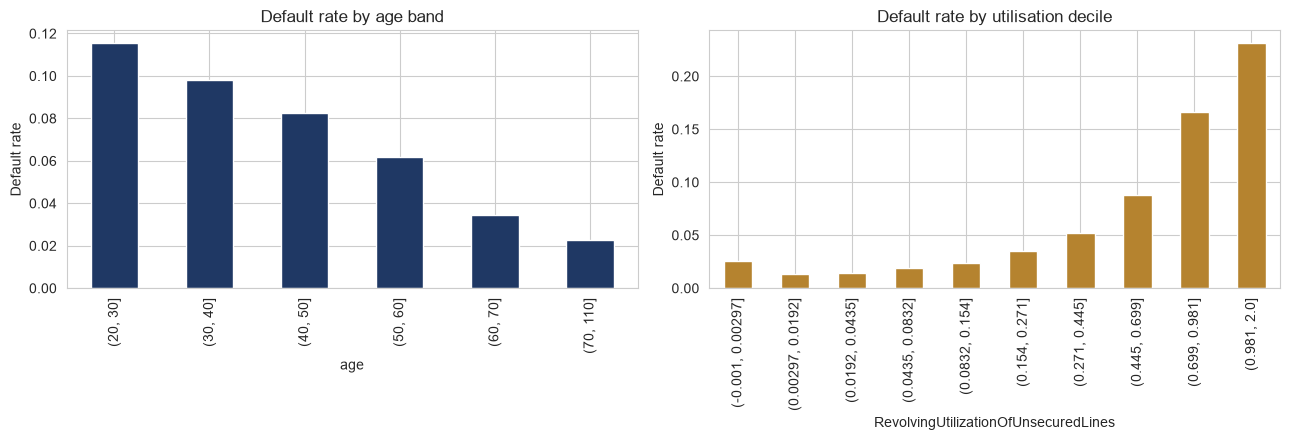

In [108]:
age_band = pd.cut(df["age"], bins=[20, 30, 40, 50, 60, 70, 110])
age_risk = df.groupby(age_band, observed=True)["SeriousDlqin2yrs"].mean()

util_band = pd.qcut(df["RevolvingUtilizationOfUnsecuredLines"], 10, duplicates="drop")
util_risk = df.groupby(util_band, observed=True)["SeriousDlqin2yrs"].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
age_risk.plot(kind="bar", ax=ax[0], color="#1F3864"); ax[0].set_title("Default rate by age band")
util_risk.plot(kind="bar", ax=ax[1], color="#B5832F"); ax[1].set_title("Default rate by utilisation decile")
for a in ax: a.set_ylabel("Default rate")
plt.tight_layout(); plt.show()

**What:** convert every predictor into **Weight of Evidence (WOE)** and rank predictors by **Information Value (IV)**.
**Why:** WOE/IV is the standard scorecard language in banks: each bin of a variable gets a number saying how much safer or riskier it is than average, and IV summarises how useful the whole variable is (rule of thumb: < 0.02 useless, 0.1–0.3 medium, > 0.3 strong).
**How:** continuous variables are cut into 10 equal-size bins; the three delinquency counts are binned by exact value (0, 1, 2, 3+) because most borrowers have zero. WOE = log(share of good ÷ share of bad) in the bin. A 0.5 smoothing constant avoids division by zero.

In [109]:
TARGET = "SeriousDlqin2yrs"

def woe_table_from_groups(grouped):
    """grouped has columns total, bad. Adds good, WOE, IV and bad rate."""
    grouped["good"] = grouped["total"] - grouped["bad"]
    tot_bad, tot_good = grouped["bad"].sum(), grouped["good"].sum()
    grouped["dist_bad"]  = (grouped["bad"]  + 0.5) / (tot_bad  + 0.5)
    grouped["dist_good"] = (grouped["good"] + 0.5) / (tot_good + 0.5)
    grouped["woe"] = np.log(grouped["dist_good"] / grouped["dist_bad"])
    grouped["iv"]  = (grouped["dist_good"] - grouped["dist_bad"]) * grouped["woe"]
    grouped["bad_rate"] = grouped["bad"] / grouped["total"]
    return grouped[["total", "bad", "bad_rate", "woe", "iv"]]

def woe_continuous(data, feature, bins=10):
    """Equal-frequency bins (10 deciles)."""
    b = pd.qcut(data[feature], bins, duplicates="drop")
    g = data.groupby(b, observed=True)[TARGET].agg(["count", "sum"])
    g.columns = ["total", "bad"]
    t = woe_table_from_groups(g)
    return t, t["iv"].sum()

def woe_discrete(data, feature, max_distinct=3):
    """Exact values up to max_distinct, everything above in one 'N+' bucket (for count variables)."""
    b = np.where(data[feature] <= max_distinct, data[feature].astype(int).astype(str), f"{max_distinct + 1}+")
    g = data.groupby(b)[TARGET].agg(["count", "sum"])
    g.columns = ["total", "bad"]
    t = woe_table_from_groups(g)
    return t, t["iv"].sum()

continuous_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
                   "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines", "NumberOfDependents"]
predictors = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
              "NumberOfOpenCreditLinesAndLoans", "NumberOfTime30-59DaysPastDueNotWorse",
              "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate",
              "NumberRealEstateLoansOrLines", "NumberOfDependents"]
flag_cols = ["Income_Missing", "Dependents_Missing"]

woe_tables, iv_rows = {}, []
for col in predictors:
    if col in delinq_cols:
        t, iv = woe_discrete(df, col, max_distinct=3)
    else:
        t, iv = woe_continuous(df, col, bins=10)
    woe_tables[col] = t
    iv_rows.append({"variable": col, "IV": iv})
for col in flag_cols:                                    # 0/1 flags: two bins, so use the discrete rule
    t, iv = woe_discrete(df, col, max_distinct=0)
    iv_rows.append({"variable": col, "IV": iv})

iv_df = pd.DataFrame(iv_rows).sort_values("IV", ascending=False).reset_index(drop=True)
print("Information Value ranking:\n", iv_df)
print("\nWorked example - WOE table for NumberOfTimes90DaysLate:")
print(woe_tables["NumberOfTimes90DaysLate"])

Information Value ranking:
                                 variable        IV
0   RevolvingUtilizationOfUnsecuredLines  1.112411
1                NumberOfTimes90DaysLate  0.829058
2   NumberOfTime30-59DaysPastDueNotWorse  0.704356
3   NumberOfTime60-89DaysPastDueNotWorse  0.553543
4                                    age  0.258905
5                              DebtRatio  0.071601
6                          MonthlyIncome  0.066920
7        NumberOfOpenCreditLinesAndLoans  0.066838
8                     NumberOfDependents  0.025003
9           NumberRealEstateLoansOrLines  0.012097
10                        Income_Missing  0.007726
11                    Dependents_Missing  0.003640

Worked example - WOE table for NumberOfTimes90DaysLate:
     total   bad  bad_rate       woe        iv
0   141931  6701  0.047213  0.368421  0.109690
1     5243  1765  0.336639 -1.958061  0.296122
2     1555   776  0.499035 -2.632373  0.189204
3      667   385  0.577211 -2.947091  0.107362
4+     604   399 

**What:** replace every raw value by its bin's WOE, split the data 70 / 30 into training and test sets, and fit the two baseline models: a **logistic regression** (the regulator-friendly scorecard) and a **gradient boosting** machine (the ML challenger).
**Why:** the logistic model is the transparent benchmark; the boosting model shows whether ML adds discrimination. AUC (0.5 = coin flip, 1 = perfect) and Gini (= 2·AUC − 1) measure how well each ranks defaulters above non-defaulters on data the model has not seen.
**How:** `stratify=y` keeps the same default share in both parts; `random_state=42` makes the split repeatable. Note: the bins above were fitted on all rows (as in the paper); a stricter validation would fit them on the training rows only.

In [110]:
X_woe = pd.DataFrame(index=df.index)
for col in predictors:
    if col in delinq_cols:
        raw = np.where(df[col] <= 3, df[col].astype(int).astype(str), "4+")
        X_woe[col + "_woe"] = pd.Series(raw, index=df.index).map(woe_tables[col]["woe"])
    else:
        bins_ = pd.qcut(df[col], 10, duplicates="drop")
        X_woe[col + "_woe"] = bins_.map(woe_tables[col]["woe"]).astype(float)
for col in flag_cols:
    X_woe[col] = df[col]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X_woe, y, test_size=0.3, random_state=SEED, stratify=y)
print("Feature matrix:", X_woe.shape, "| missing values:", int(X_woe.isnull().sum().sum()))
print("Train default rate:", round(y_train.mean(), 4), "| Test default rate:", round(y_test.mean(), 4))

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
logreg_probs = logreg.predict_proba(X_test)[:, 1]
gbm = GradientBoostingClassifier(random_state=SEED).fit(X_train, y_train)
gbm_probs = gbm.predict_proba(X_test)[:, 1]

for name, p in [("Logistic Regression", logreg_probs), ("Gradient Boosting", gbm_probs)]:
    auc = roc_auc_score(y_test, p)
    print(f"{name:20s} AUC {auc:.4f}   Gini {2 * auc - 1:.4f}")

print("\nLogistic regression coefficients (WOE scale):")
print(pd.DataFrame({"feature": X_woe.columns, "coefficient": logreg.coef_[0]}).sort_values("coefficient"))

Feature matrix: (150000, 12) | missing values: 0
Train default rate: 0.0668 | Test default rate: 0.0668
Logistic Regression  AUC 0.8551   Gini 0.7102
Gradient Boosting    AUC 0.8603   Gini 0.7206

Logistic regression coefficients (WOE scale):
                                     feature  coefficient
8           NumberRealEstateLoansOrLines_woe    -0.883237
2                              DebtRatio_woe    -0.783708
0   RevolvingUtilizationOfUnsecuredLines_woe    -0.631936
7                NumberOfTimes90DaysLate_woe    -0.535804
5   NumberOfTime30-59DaysPastDueNotWorse_woe    -0.520967
1                                    age_woe    -0.431427
6   NumberOfTime60-89DaysPastDueNotWorse_woe    -0.410622
4        NumberOfOpenCreditLinesAndLoans_woe    -0.207102
3                          MonthlyIncome_woe    -0.188507
9                     NumberOfDependents_woe    -0.181533
11                        Dependents_Missing    -0.165128
10                            Income_Missing     0.148404


**What:** two more validation numbers — the **KS statistic** and a **calibration table**.
**Why:** AUC only checks *ranking*. IFRS 9 needs the PD *level* to be right as well: if the model says 5 % for a group, about 5 % of that group should default. KS is the largest gap between the score distributions of defaulters and non-defaulters (higher = better separation).
**How:** sort test borrowers into 10 equal groups by predicted PD, then compare average predicted PD with the actual default rate in each group.

In [111]:
def ks_stat(y_true, y_prob):
    return ks_2samp(y_prob[y_true == 1], y_prob[y_true == 0]).statistic

def calibration_table(y_true, y_prob, bins=10):
    t = pd.DataFrame({"y": y_true, "p": y_prob})
    t["decile"] = pd.qcut(t["p"], bins, duplicates="drop")
    out = t.groupby("decile", observed=True).agg(n=("y", "count"),
                                                 mean_predicted_pd=("p", "mean"),
                                                 observed_default_rate=("y", "mean"))
    out["gap"] = out["observed_default_rate"] - out["mean_predicted_pd"]
    return out

print("KS  logistic:", round(ks_stat(y_test.values, logreg_probs), 4), "| KS boosting:", round(ks_stat(y_test.values, gbm_probs), 4))
print("\nCalibration - logistic regression:\n", calibration_table(y_test.values, logreg_probs))
print("\nCalibration - gradient boosting:\n", calibration_table(y_test.values, gbm_probs))

KS  logistic: 0.5558 | KS boosting: 0.5655

Calibration - logistic regression:
                       n  mean_predicted_pd  observed_default_rate       gap
decile                                                                     
(0.00425, 0.0102]  4500           0.008420               0.004222 -0.004198
(0.0102, 0.0132]   4500           0.011661               0.006000 -0.005661
(0.0132, 0.0163]   4500           0.014715               0.009778 -0.004937
(0.0163, 0.0204]   4500           0.018254               0.014444 -0.003810
(0.0204, 0.026]    4500           0.023048               0.022222 -0.000826
(0.026, 0.0353]    4500           0.030223               0.029111 -0.001112
(0.0353, 0.0517]   4501           0.042725               0.040880 -0.001845
(0.0517, 0.0802]   4499           0.064706               0.067348  0.002642
(0.0802, 0.139]    4500           0.104341               0.121778  0.017437
(0.139, 0.933]     4500           0.342732               0.352667  0.009935

Calibra

**What (optional):** explain the boosting model with **SHAP** — which variables push an individual borrower's PD up or down.
**Why:** the ECB expects ML models to be explainable; SHAP is the usual tool. This cell is optional and **has not been run by the author of this notebook** (the package could not be installed in the environment used to build it).
**How:** `pip install shap`, then run. If the package is missing the cell just prints a message.

                                     feature  mean_abs_shap
0   RevolvingUtilizationOfUnsecuredLines_woe       0.611622
1   NumberOfTime30-59DaysPastDueNotWorse_woe       0.268131
2                NumberOfTimes90DaysLate_woe       0.230888
3                                    age_woe       0.207029
4                              DebtRatio_woe       0.120426
5   NumberOfTime60-89DaysPastDueNotWorse_woe       0.111099
6        NumberOfOpenCreditLinesAndLoans_woe       0.078559
7                          MonthlyIncome_woe       0.065992
8           NumberRealEstateLoansOrLines_woe       0.054717
9                     NumberOfDependents_woe       0.011501
10                            Income_Missing       0.005163
11                        Dependents_Missing       0.000022


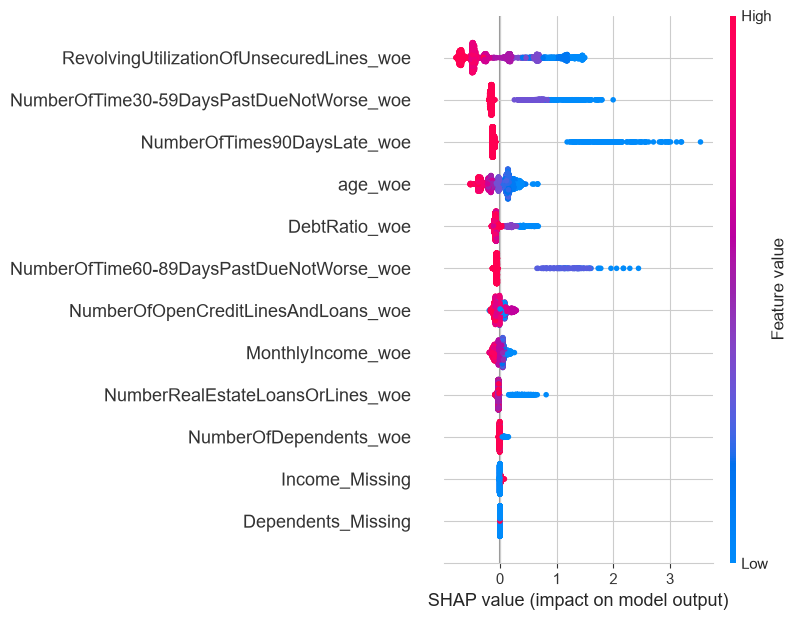

In [112]:
try:
    import shap
    explainer = shap.TreeExplainer(gbm)
    sample = X_test.sample(3000, random_state=SEED)          # a sample keeps it fast
    shap_values = explainer.shap_values(sample)
    ranking = (pd.DataFrame({"feature": sample.columns, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
               .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
    print(ranking)
    shap.summary_plot(shap_values, sample, show=True)
except ImportError:
    print("shap is not installed - skip this cell, or run:  pip install shap")

---
# Part 2 — Building the tone index from central-bank statements
*Goal of this part: turn each ECB / FOMC statement into one number, "net negative tone", that can later be attached to loans.*

**What:** score every statement: count negative and positive finance-words and divide the difference by the length.
**Why:** this is the standard dictionary method (Loughran–McDonald). **net tone = (negative words − positive words) / total words**, so a **higher number means a more negative statement**.
**How:** the cell reads one text file per statement (the date is in the file name), scores it, and saves a table. If the folder is missing it loads the already-scored table instead. Choose the word list with `SCORING` in the Settings cell. Caveat: the official and hand-built lists agree only moderately on the ECB (correlation about 0.54 on 55 shared dates), so tone is a *noisy* measure.

Scoring ecb_statements_all with the 'handbuilt' word list ...
Scoring fomc_statements with the 'handbuilt' word list ...

ECB: 165 statements, 2009-01-15 to 2026-09-10
count    165.00000
mean      -0.00225
std        0.00695
min       -0.03132
25%       -0.00534
50%       -0.00159
75%        0.00284
max        0.00787
Name: net_sentiment, dtype: float64

FOMC: 75 statements, 2007-01-31 to 2015-12-16
count    75.00000
mean     -0.00902
std       0.00826
min      -0.03030
25%      -0.01275
50%      -0.00998
75%      -0.00647
max       0.01953
Name: net_sentiment, dtype: float64


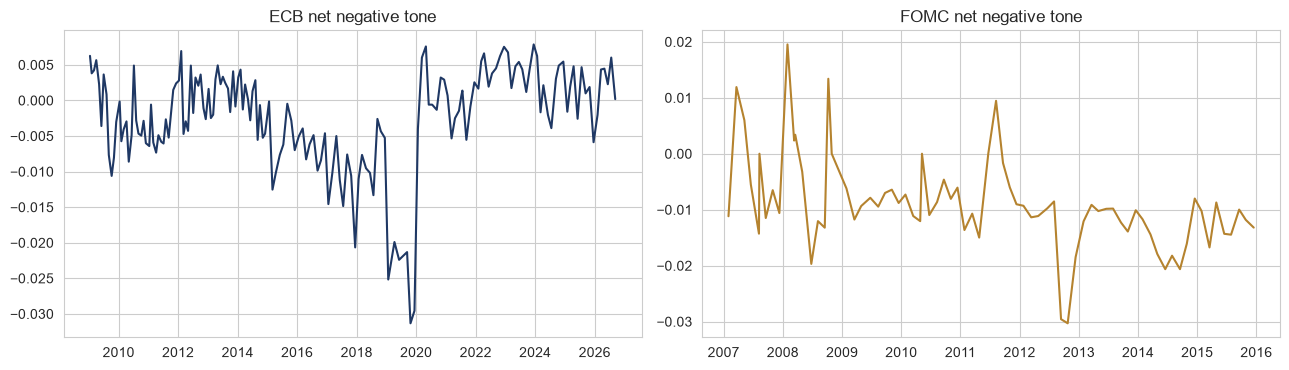

In [113]:
import re

def score_handbuilt(text):
    from lm_lexicon import score_text                    # file lm_lexicon.py must sit next to this notebook
    return score_text(text)

def score_official(text):
    import pysentiment2 as ps
    lm = ps.LM()
    tokens = lm.tokenize(text)
    s = lm.get_score(tokens)
    n = len(tokens)
    return {"num_words": n, "negative_count": s["Negative"], "positive_count": s["Positive"],
            "net_sentiment": (s["Negative"] - s["Positive"]) / n if n else 0.0}

score_fn = score_handbuilt if SCORING == "handbuilt" else score_official

def build_tone_series(folder, out_csv):
    rows = []
    for fp in sorted(Path(folder).glob("*.txt")):
        m = re.search(r"(\d{4})-(\d{2})-(\d{2})", fp.name)
        if not m:
            print("no date in file name, skipped:", fp.name); continue
        rows.append({"file": fp.name, "date": "-".join(m.groups()),
                     **score_fn(fp.read_text(encoding="utf-8", errors="ignore"))})
    out = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    out.to_csv(out_csv, index=False)
    return out

def get_tone(folder, csv_path):
    if Path(folder).exists() and any(Path(folder).glob("*.txt")):
        print(f"Scoring {folder.name} with the '{SCORING}' word list ...")
        t = build_tone_series(folder, csv_path)
    else:
        print(f"Folder {folder.name} not found - loading the saved scores instead: {csv_path.name}")
        t = pd.read_csv(csv_path)
    t["date"] = pd.to_datetime(t["date"])
    return t.sort_values("date").reset_index(drop=True)

ecb_tone  = get_tone(ECB_DIR,  ECB_TONE_CSV)
fomc_tone = get_tone(FOMC_DIR, FOMC_TONE_CSV)

for name, t in [("ECB", ecb_tone), ("FOMC", fomc_tone)]:
    print(f"\n{name}: {len(t)} statements, {t['date'].min().date()} to {t['date'].max().date()}")
    print(t["net_sentiment"].describe().round(5))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(ecb_tone["date"], ecb_tone["net_sentiment"], color="#1F3864"); ax[0].set_title("ECB net negative tone")
ax[1].plot(fomc_tone["date"], fomc_tone["net_sentiment"], color="#B5832F"); ax[1].set_title("FOMC net negative tone")
plt.tight_layout(); plt.show()

---
# Part 3 — Does tone help? And does a *fake* tone help just as much?
*Goal: reproduce the "naive" finding and then break it with placebos. Two datasets: Lending Club (US, with FOMC tone) and Bondora (euro-area, with ECB tone).*

**The idea in one picture.** Every loan has an origination date. We attach to each loan the tone of the **most recent statement published before that date** (so no look-ahead). Because tone depends only on the date, a flexible model can use it to learn "this loan is from a bad year". A **placebo** keeps the same set of tone values but shuffles them across statement dates, which destroys any real link between wording and economy while keeping the date-clock effect. If the placebo helps as much as the real tone, the "improvement" is a clock, not information.

**What:** define the helper functions used by both datasets.
**Why:** the same test must be applied identically to Lending Club and Bondora — and identically to real and fake tone — otherwise the comparison is unfair.
**How:**
* `attach_tone` — joins each loan to the latest earlier statement (`merge_asof`, backward); with `shuffle_seed` it first shuffles the tone values across dates (the placebo).
* `auc_gain` — trains the model *without* tone and *with* tone on the same split and returns the change in test AUC. The split is either random 75/25 or **out-of-time** (train on earlier loans, test on later ones).
* `boot_ci` — bootstrap interval for that AUC gain (the "naive significance" a reader would see).

In [114]:
def new_gbm():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=SEED)

def attach_tone(loans, date_col, tone, shuffle_seed=None, must_have=()):
    t = tone[["date", "net_sentiment"]].sort_values("date").copy()
    if shuffle_seed is not None:                      # PLACEBO: same values, wrong dates
        t["net_sentiment"] = np.random.default_rng(shuffle_seed).permutation(t["net_sentiment"].values)
    out = pd.merge_asof(loans.sort_values(date_col), t, left_on=date_col, right_on="date", direction="backward")
    return out.dropna(subset=["net_sentiment"] + list(must_have)).reset_index(drop=True)

def auc_gain(m, base_feats, y_col, date_col, cut=None, keep_probs=False):
    y = m[y_col].values
    if cut is None:
        tr, te = train_test_split(np.arange(len(m)), test_size=0.25, random_state=SEED, stratify=y)
    else:
        tr = np.where(m[date_col] < pd.Timestamp(cut))[0]
        te = np.where(m[date_col] >= pd.Timestamp(cut))[0]
    aug_feats = base_feats + ["net_sentiment"]
    g0 = new_gbm().fit(m.iloc[tr][base_feats], y[tr])
    g1 = new_gbm().fit(m.iloc[tr][aug_feats], y[tr])
    p0 = g0.predict_proba(m.iloc[te][base_feats])[:, 1]
    p1 = g1.predict_proba(m.iloc[te][aug_feats])[:, 1]
    gain = roc_auc_score(y[te], p1) - roc_auc_score(y[te], p0)
    return (gain, y[te], p0, p1) if keep_probs else gain

def boot_ci(y, p0, p1, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() in (0, len(i)): continue
        d.append(roc_auc_score(y[i], p1[i]) - roc_auc_score(y[i], p0[i]))
    d = np.array(d)
    return np.percentile(d, [2.5, 97.5]), (d <= 0).mean()

def real_vs_placebo(loans, date_col, tone, base_feats, y_col, cut, label, must_have=()):
    """Prints the naive result and the placebo comparison for one dataset."""
    real_df = attach_tone(loans, date_col, tone, must_have=must_have)
    gain, y_te, p0, p1 = auc_gain(real_df, base_feats, y_col, date_col, keep_probs=True)
    lo_hi, p_le0 = boot_ci(y_te, p0, p1)
    print(f"[{label}] NAIVE random split: AUC gain {gain:+.4f}, bootstrap 95% CI [{lo_hi[0]:+.4f}, {lo_hi[1]:+.4f}], P(gain<=0) = {p_le0:.3f}")
    gain_oot = auc_gain(real_df, base_feats, y_col, date_col, cut=cut)
    print(f"[{label}] NAIVE out-of-time (test from {cut}): AUC gain {gain_oot:+.4f}")
    pl_r, pl_o = [], []
    for s in range(N_PLACEBOS):
        pdf = attach_tone(loans, date_col, tone, shuffle_seed=s, must_have=must_have)
        pl_r.append(auc_gain(pdf, base_feats, y_col, date_col))
        pl_o.append(auc_gain(pdf, base_feats, y_col, date_col, cut=cut))
    pl_r, pl_o = np.array(pl_r), np.array(pl_o)
    print(f"[{label}] PLACEBO random split : mean {pl_r.mean():+.4f}, range [{pl_r.min():+.4f}, {pl_r.max():+.4f}] | real beats {int((pl_r < gain).sum())}/{N_PLACEBOS}")
    print(f"[{label}] PLACEBO out-of-time  : mean {pl_o.mean():+.4f}, range [{pl_o.min():+.4f}, {pl_o.max():+.4f}] | real beats {int((pl_o < gain_oot).sum())}/{N_PLACEBOS}")
    return dict(real=gain, real_oot=gain_oot, placebo=pl_r, placebo_oot=pl_o)

**What:** load the Lending Club loans and build the 0/1 default flag.
**Why:** we need a clean outcome (charged off / default = 1, fully paid = 0) and an origination date. Only loans with a final outcome are kept.
**How:** keep the 12 baseline variables used in the paper; turn the grade letter into a number (A = 1 … G = 7); turn employment length and term into numbers.

In [115]:
LC_FEATURES = ["dti", "annual_inc", "revol_util", "delinq_2yr", "grade_num", "int_rate",
               "emp_length_num", "term_num", "open_acc", "pub_rec", "inq_last_6mths", "total_acc"]
DEFAULT_STATUS = {"Charged Off", "Default", "Does not meet the credit policy. Status:Charged Off"}
PAID_STATUS    = {"Fully Paid", "Does not meet the credit policy. Status:Fully Paid"}

need = {"loan_status", "issue_d", "dti", "annual_inc", "revol_util", "delinq_2yrs", "delinq_2yr",
        "grade", "int_rate", "emp_length", "term", "open_acc", "pub_rec", "inq_last_6mths", "total_acc"}
pieces = []
for chunk in pd.read_csv(LC_CSV, usecols=lambda c: c in need, chunksize=200_000, low_memory=False):
    chunk = chunk[chunk["loan_status"].isin(DEFAULT_STATUS | PAID_STATUS)]
    year = pd.to_datetime(chunk["issue_d"], format="%b-%Y", errors="coerce").dt.year
    pieces.append(chunk[year <= 2015])      # the paper uses loans issued 2007-2015
lc = pd.concat(pieces, ignore_index=True)
print("Lending Club rows kept:", len(lc))
lc = lc.rename(columns={"delinq_2yrs": "delinq_2yr"})
lc = lc[lc["loan_status"].isin(DEFAULT_STATUS | PAID_STATUS)].copy()
lc["default"] = lc["loan_status"].isin(DEFAULT_STATUS).astype(int)
lc["issue_date"] = pd.to_datetime(lc["issue_d"], format="%b-%Y", errors="coerce")
lc = lc.dropna(subset=["issue_date"])
lc["grade_num"] = lc["grade"].map({g: i for i, g in enumerate("ABCDEFG", start=1)})

def emp_years(x):
    if pd.isna(x): return np.nan
    x = str(x)
    if "10+" in x: return 10
    if "< 1" in x: return 0
    d = "".join(c for c in x if c.isdigit())
    return float(d) if d else np.nan
lc["emp_length_num"] = lc["emp_length"].apply(emp_years)
lc["term_num"] = lc["term"].astype(str).str.extract(r"(\d+)").astype(float)
if lc["revol_util"].dtype == object:
    lc["revol_util"] = lc["revol_util"].astype(str).str.replace("%", "", regex=False).astype(float)

LC_FEATURES = [f for f in LC_FEATURES if f in lc.columns]
lc = lc[["issue_date", "default"] + LC_FEATURES]
print(f"Lending Club: {len(lc):,} resolved loans, {lc['issue_date'].min().date()} to {lc['issue_date'].max().date()}, default rate {lc['default'].mean():.2%}")

Lending Club rows kept: 256939
Lending Club: 256,939 resolved loans, 2007-06-01 to 2015-12-01, default rate 18.38%


**What:** Lending Club × FOMC — the naive test, the out-of-time test and the placebo test.
**Why:** this is the paper's Table 9–10 logic: if the real tone's gain is no larger than the shuffled tone's gain, tone adds nothing beyond the date.
**How:** loans with a missing baseline variable are dropped (`must_have`), then `real_vs_placebo` runs everything. Expect a naive gain of about +0.0075 that the placebos match (mean ≈ +0.0076). This cell takes several minutes at full size. Note that the paper's naive Table 9 used the slower `GradientBoostingClassifier`; here the faster histogram version is used for real and placebo alike so they are strictly comparable.

In [116]:
res_lc = real_vs_placebo(lc, "issue_date", fomc_tone, LC_FEATURES, "default", OOT_CUT_LC,
                         "Lending Club x FOMC", must_have=LC_FEATURES)

[Lending Club x FOMC] NAIVE random split: AUC gain +0.0075, bootstrap 95% CI [+0.0063, +0.0086], P(gain<=0) = 0.000
[Lending Club x FOMC] NAIVE out-of-time (test from 2014-01-01): AUC gain -0.0047
[Lending Club x FOMC] PLACEBO random split : mean +0.0076, range [+0.0043, +0.0098] | real beats 5/10
[Lending Club x FOMC] PLACEBO out-of-time  : mean -0.0027, range [-0.0060, +0.0004] | real beats 3/10


**What:** load the Bondora loans and define "default within 12 months".
**Why:** Bondora is a European (Finland, Estonia, Spain, Slovakia, Netherlands) loan book, so the ECB tone is the relevant narrative. Only loans old enough to have a full 12-month window are kept, otherwise recent loans would look artificially safe.
**How:** default = the default date falls within 365 days of the loan date. The 1 % largest values of income, amount and liabilities are capped to tame outliers. Country is turned into 0/1 columns.

**What:** Bondora × ECB — the same naive, out-of-time and placebo tests.
**Why:** a second dataset with a different central bank shows the pattern is not a Lending Club accident.
**How:** same function as before. Expect (paper Table 11) a small positive real gain out of time but placebos that sometimes do better, so the real tone beats only about 6 of 10 placebos.

In [122]:
RATING_ORDER = {"AA": 1, "A": 2, "B": 3, "C": 4, "D": 5, "E": 6, "F": 7, "HR": 8}
BONDORA_NUMERIC = ["Age", "Interest", "LoanDuration", "Amount", "DebtToIncome", "IncomeTotal",
                   "LiabilitiesTotal", "ExistingLiabilities", "NoOfPreviousLoansBeforeLoan",
                   "NewCreditCustomer", "rating_num"]
cols = ["ReportAsOfEOD", "LoanDate", "DefaultDate", "Country", "Rating"] + [c for c in BONDORA_NUMERIC if c != "rating_num"]

pieces = []
for i, chunk in enumerate(pd.read_csv(BONDORA_CSV, usecols=cols, chunksize=20_000, low_memory=False)):
    pieces.append(chunk)
bond = pd.concat(pieces, ignore_index=True)
del pieces
for c in [c for c in BONDORA_NUMERIC if c != "rating_num"]:
    bond[c] = pd.to_numeric(bond[c], errors="coerce")

report_date = pd.to_datetime(bond["ReportAsOfEOD"].iloc[0])
bond["LoanDate"] = pd.to_datetime(bond["LoanDate"], errors="coerce")
bond["DefaultDate"] = pd.to_datetime(bond["DefaultDate"], errors="coerce")
bond = bond.dropna(subset=["LoanDate"])
bond = bond[bond["LoanDate"] <= report_date - pd.Timedelta(days=365)].copy()

days_to_default = (bond["DefaultDate"] - bond["LoanDate"]).dt.days
bond["default12"] = ((days_to_default >= 0) & (days_to_default <= 365)).astype(int)
bond["rating_num"] = bond["Rating"].map(RATING_ORDER)
bond["NewCreditCustomer"] = bond["NewCreditCustomer"].astype(float)
for c in ["IncomeTotal", "Amount", "LiabilitiesTotal", "ExistingLiabilities"]:
    bond[c] = bond[c].clip(upper=bond[c].quantile(0.99))
for c in bond["Country"].dropna().unique():
    bond[f"ctry_{c}"] = (bond["Country"] == c).astype(float)

BONDORA_FEATURES = BONDORA_NUMERIC + [c for c in bond.columns if c.startswith("ctry_")]
print(f"Bondora: {len(bond):,} loans, {bond['LoanDate'].min().date()} to {bond['LoanDate'].max().date()}, 12-month default rate {bond['default12'].mean():.2%}")

Bondora: 306,034 loans, 2009-02-28 to 2023-05-25, 12-month default rate 20.36%


In [ ]:
res_bond = real_vs_placebo(bond, "LoanDate", ecb_tone, BONDORA_FEATURES, "default12", OOT_CUT_BONDORA, "Bondora x ECB")

---
# Part 4 — The proper test: control for the origination period
*Goal: ask whether tone still explains defaults once everything common to loans of the same period (year, half-year or quarter) is removed. The only variation left is **between statements inside the same period**, so the effective sample is the number of statement-period units (65–158), not the number of loans (hundreds of thousands).*

**Plan of the test (5 steps)**
1. Fit a baseline logit with loan characteristics **and period dummies** (no tone).
2. Take the residual = actual default − predicted default, and average it per statement.
3. Regress these statement-level residuals on the **within-period** tone (tone minus its period average), weighted by number of loans.
4. Get a p-value by **shuffling tone among statements inside the same period** (5,000 times).
5. Repeat for the *gap* between high-risk and low-risk borrowers (does tone matter more for riskier loans?).

**What:** define the statement-level test functions.
**Why:** the permutation p-value answers "how often would a *random* ordering of the tones inside each period give a slope this large?" — it respects the small effective sample and needs no normality assumption.
**How:** `statement_table` collapses loans to one row per statement-period; `wslope` is a weighted regression slope; `perm_test` shuffles tone within periods; `baseline_resid` fits the no-tone model; `predictive` re-runs the boosting model with period dummies and compares the real within-period tone against placebos.

In [123]:
RNG = np.random.default_rng(7)

def statement_table(d, resid_col, stmt_col, vint_col, tone_col, risk_col):
    rows = []
    for (s, v), x in d.groupby([stmt_col, vint_col]):
        lo, hi = x[x[risk_col] == 0], x[x[risk_col] == 1]
        rows.append(dict(stmt=s, vint=v, n=len(x), r=x[resid_col].mean(), tone=x[tone_col].iloc[0],
                         r_lo=lo[resid_col].mean() if len(lo) else np.nan,
                         r_hi=hi[resid_col].mean() if len(hi) else np.nan))
    return pd.DataFrame(rows)

def wslope(x, y, w):
    xm, ym = np.average(x, weights=w), np.average(y, weights=w)
    return np.sum(w * (x - xm) * (y - ym)) / np.sum(w * (x - xm) ** 2)

def perm_test(t, ycol, tone_col="tone", n_perm=None, min_n=30):
    n_perm = n_perm or N_PERM
    t = t.dropna(subset=[ycol]).copy()
    t = t[t["n"] >= min_n]
    t = t[t.groupby("vint")["stmt"].transform("count") >= 2].copy()     # need a neighbour in the same period
    if len(t) < 6:
        return dict(slope=np.nan, p=np.nan, n_stmt=len(t))
    t["x"] = t[tone_col] - t.groupby("vint")[tone_col].transform("mean")
    t["y"] = t[ycol] - t.groupby("vint")[ycol].transform("mean")
    w = t["n"].values.astype(float)
    obs = wslope(t["x"].values, t["y"].values, w)
    vint, tone = t["vint"].values, t[tone_col].values
    groups = [np.where(vint == v)[0] for v in np.unique(vint)]
    hits = 0
    for _ in range(n_perm):
        tp = tone.copy()
        for gi in groups:
            tp[gi] = RNG.permutation(tone[gi])
        xp = tp - pd.Series(tp).groupby(vint).transform("mean").values
        if abs(wslope(xp, t["y"].values, w)) >= abs(obs):
            hits += 1
    return dict(slope=obs, p=(hits + 1) / (n_perm + 1), n_stmt=len(t), sd_tone=float(t["x"].std()))

def baseline_resid(d, feats, vint_col):
    V = pd.get_dummies(d[vint_col].astype(str), prefix="v", dtype=float)
    X = pd.concat([d[feats].reset_index(drop=True), V.reset_index(drop=True)], axis=1)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=1e4, max_iter=3000))
    pipe.fit(X, d["y"].values)
    return d["y"].values - pipe.predict_proba(X)[:, 1]

def predictive(d, feats, vint_col, label):
    """Boosting AUC with period dummies: baseline vs + within-period tone vs + shuffled tone (placebos)."""
    V = pd.get_dummies(d[vint_col].astype(str), prefix="v", dtype=float)
    base = pd.concat([d[feats].reset_index(drop=True), V.reset_index(drop=True)], axis=1)
    y = d["y"].values
    tr, te = train_test_split(np.arange(len(d)), test_size=0.25, random_state=SEED, stratify=y)
    def auc(X):
        m = new_gbm().fit(X.iloc[tr], y[tr])
        return roc_auc_score(y[te], m.predict_proba(X.iloc[te])[:, 1])
    a0 = auc(base)
    real = auc(base.assign(tone_dev=(d["tone"] - d.groupby(vint_col)["tone"].transform("mean")).values))
    st = d[["stmt", vint_col, "tone"]].drop_duplicates("stmt").copy()
    pl = []
    for s in range(N_PLACEBOS):
        st["tone_p"] = np.random.default_rng(s).permutation(st["tone"].values)
        dd = d[["stmt"]].merge(st[["stmt", "tone_p"]], on="stmt", how="left")
        dd[vint_col] = d[vint_col].values
        dev = dd["tone_p"].values - dd.groupby(vint_col)["tone_p"].transform("mean").values
        pl.append(auc(base.assign(tone_dev=dev)) - a0)
    pl = np.array(pl)
    print(f"[{label}] AUC with period dummies {a0:.4f} | + real within-period tone {real:.4f} (gain {real - a0:+.4f}) | "
          f"placebo gains mean {pl.mean():+.4f}, range [{pl.min():+.4f}, {pl.max():+.4f}] | real beats {int((pl < real - a0).sum())}/{N_PLACEBOS}")

def period_control_test(d, feats, label, period_cols=("yr", "h", "q")):
    global RNG
    RNG = np.random.default_rng(7)          # same shuffles every time this test is run
    print(f"\n==================== {label} ====================")
    print(f"loans {len(d):,}; statements {d['stmt'].nunique()}; default rate {d['y'].mean():.2%}")
    names = {"yr": "year", "h": "half-year", "q": "quarter"}
    for vc in period_cols:
        print(f"\n--- period control: {names[vc]} ({d[vc].nunique()} dummies) ---")
        d["e"] = baseline_resid(d, feats, vc)
        t = statement_table(d, "e", "stmt", vc, "tone", "risk_hi")
        main = perm_test(t, "r")
        print(f"MAIN      residual default vs within-period tone: slope {main['slope']:+.5f}  "
              f"(1 sd of tone = {main.get('sd_tone', np.nan):.5f})  permutation p = {main['p']:.3f}  [{main['n_stmt']} statement-period units]")
        t["gap"] = t["r_hi"] - t["r_lo"]
        inter = perm_test(t, "gap")
        print(f"INTERACT  high-risk minus low-risk gap vs tone:   slope {inter['slope']:+.5f}  permutation p = {inter['p']:.3f}  [{inter['n_stmt']} units]")
        predictive(d, feats, vc, f"{label}/{names[vc]}")

**What:** run the same test on **Lending Club × FOMC**.
**Why:** a second dataset (paper Table 12). Here the *annual* control leaves a small p-value (about 0.02) — the one place where something survives — but it disappears as the period control becomes finer (half-year p about 0.23, quarter about 0.60), and even under year effects the real tone's AUC gain (+0.0046) is only about 0.0004 above the placebo mean (+0.0042).
**How:** "high risk" = grades E, F, G. Rows are shuffled with a fixed seed (and capped at `LC_MAX_ROWS` if the file is larger).

In [125]:
fe_lc = attach_tone(lc, "issue_date", fomc_tone, must_have=LC_FEATURES)   # loans with a missing baseline variable are dropped
fe_lc = fe_lc[fe_lc["issue_date"] >= "2008-01-01"]
fe_lc = fe_lc.sample(n=min(LC_MAX_ROWS, len(fe_lc)), random_state=1)      # also shuffles the row order, as in the paper run
fe_lc = fe_lc.rename(columns={"default": "y", "net_sentiment": "tone", "date": "stmt"})
fe_lc["risk_hi"] = (fe_lc["grade_num"] >= 5).astype(int)
fe_lc = add_periods(fe_lc, "issue_date")
period_control_test(fe_lc, LC_FEATURES, "LENDING CLUB x FOMC")


==================== LENDING CLUB x FOMC ====================
loans 246,134; statements 64; default rate 18.04%

--- period control: year (8 dummies) ---
MAIN      residual default vs within-period tone: slope +1.25708  (1 sd of tone = 0.00633)  permutation p = 0.020  [65 statement-period units]
INTERACT  high-risk minus low-risk gap vs tone:   slope +1.32966  permutation p = 0.250  [65 units]
[LENDING CLUB x FOMC/year] AUC with period dummies 0.7132 | + real within-period tone 0.7178 (gain +0.0046) | placebo gains mean +0.0042, range [+0.0034, +0.0046] | real beats 10/10

--- period control: half-year (16 dummies) ---
MAIN      residual default vs within-period tone: slope +0.47013  (1 sd of tone = 0.00512)  permutation p = 0.234  [65 statement-period units]
INTERACT  high-risk minus low-risk gap vs tone:   slope -0.08289  permutation p = 0.942  [65 units]
[LENDING CLUB x FOMC/half-year] AUC with period dummies 0.7170 | + real within-period tone 0.7173 (gain +0.0003) | placebo gains 

---
# Part 5 — Can a feature-importance report tell a real driver from a clock?
*Goal: regulators and validators often accept "the feature ranks high in the importance report" as evidence it matters. We test that claim.*

**What:** train the Bondora boosting model once with the real tone and five times with shuffled (placebo) tone, and measure each tone's **permutation importance** (how much the AUC drops when that column is scrambled).
**Why:** if shuffled tones also rank high, the report cannot distinguish a genuine driver from a time proxy.
**How:** 30,000 test loans, 3 repeats. Expected (paper Table 13): real tone ranks about 3rd of 17; placebo tones rank 6th–13th but still earn roughly 15–39 % of the real tone's importance. So the real tone does stand out a little — but placebo tones are not zero, so a high rank alone is not proof.

In [ ]:
def add_periods(d, date_col):
    d["yr"] = d[date_col].dt.year.astype(str)
    d["h"]  = d[date_col].dt.year.astype(str) + "H" + ((d[date_col].dt.month - 1) // 6 + 1).astype(str)
    d["q"]  = d[date_col].dt.to_period("Q").astype(str)
    return d

fe_bond = attach_tone(bond, "LoanDate", ecb_tone)
fe_bond = fe_bond.rename(columns={"default12": "y", "net_sentiment": "tone", "date": "stmt"})
fe_bond["risk_hi"] = (fe_bond["rating_num"] >= 6).astype(int)
fe_bond = add_periods(fe_bond, "LoanDate")
print("table ready:", len(fe_bond), "loans", flush=True)
period_control_test(fe_bond, BONDORA_FEATURES, "BONDORA x ECB", period_cols=("yr", "h", "q"))

In [ ]:
rows = []
for label, seed in [("REAL", None)] + [(f"PLACEBO{s}", s) for s in range(2)]:
    d = attach_tone(bond, "LoanDate", ecb_tone, shuffle_seed=seed)
    feats = BONDORA_FEATURES + ["net_sentiment"]
    y_ = d["default12"].values
    tr, te = train_test_split(np.arange(len(d)), test_size=0.25, random_state=SEED, stratify=y_)
    model = new_gbm().fit(d.iloc[tr][feats], y_[tr])
    sub = np.random.default_rng(1).choice(te, size=min(10000, len(te)), replace=False)
    pi = permutation_importance(model, d.iloc[sub][feats], y_[sub], scoring="roc_auc",
                                n_repeats=1, random_state=SEED, n_jobs=1)
    order = [n for n, _ in sorted(zip(feats, pi.importances_mean), key=lambda t: -t[1])]
    rows.append({"series": label,
                 "importance": pi.importances_mean[feats.index("net_sentiment")],
                 "rank": order.index("net_sentiment") + 1, "of": len(feats)})
    print(label, "done", flush=True)
imp = pd.DataFrame(rows)
imp["share_of_real"] = imp["importance"] / imp.loc[0, "importance"]
print(imp.round(5))

---
# Part 6 — How often does the *standard* check pass a meaningless series?
*Goal: measure, not just illustrate, how misleading the usual evidence is. The "standard check" is: add the feature, and call it an improvement if the 95% bootstrap interval of the test-AUC gain lies above zero.*

**The idea.** We make many fake tone series that carry **no information about borrowers**, feed each one through the standard check, and count how many "pass". Three kinds of fake series, because real tone is slow-moving:
* **shuffle** — the real tone values in random order across statements;
* **random walk** — a drifting series with no memory of the real one;
* **autoregressive** — a series with the same persistence (lag-one autocorrelation about 0.7) as the real tone.

We do this with **no period control**, with **year effects** and with **quarter effects** (the fake tone enters as its deviation from the period average).

**Two honesty points.** (1) The bootstrap here resamples only the test loans and ignores the noise from refitting the model, so its interval is too narrow: the numbers are *pass rates of the standard check*, not calibrated false-positive rates (in the paper, 75 of 180 Bondora placebos are *significantly negative* with quarter effects, which a calibrated test would not give). (2) Because the real tone is one more series next to the placebos, the **recommended test** is the **empirical-null p-value** = (1 + number of placebos whose gain is at least the real gain) / (1 + number of placebos). It needs no bootstrap interval.

**What:** define the three fake-series generators and the experiment function.
**Why:** every fake series must be pushed through exactly the same pipeline as the real tone, otherwise the pass rate means nothing.
**How:**
* `make_placebo` — builds one fake series of the requested kind with the same mean and spread as the real tone.
* `pass_rate_experiment` — attaches the series to loans through the same statement numbers as the real tone, trains the model once without tone (the baseline) and once per series with it, and reports for each series the AUC gain and whether the bootstrap interval of the gain is above zero (`passes`) or below zero (`significantly_negative`). With `period` set, year or quarter dummies are added to the baseline and the series is demeaned within each period. It also returns the real tone's gain and its empirical-null p-value.

In [127]:
def make_placebo(kind, real, rng):
    n, mu, sd = len(real), real.mean(), real.std()
    if kind == "shuffle":
        return rng.permutation(real)
    if kind == "randomwalk":
        z = np.cumsum(rng.standard_normal(n))
    else:                                                  # "autoregressive"
        phi = np.corrcoef(real[:-1], real[1:])[0, 1]      # persistence of the real series
        e = rng.standard_normal(n); z = np.zeros(n)
        for t in range(1, n):
            z[t] = phi * z[t - 1] + e[t]
    return mu + sd * (z - z.mean()) / z.std()

def pass_rate_experiment(d, feats, tone, period=None, label=""):
    tone = tone.sort_values("date").reset_index(drop=True)
    real = tone["net_sentiment"].values
    sid = np.searchsorted(tone["date"].values, d["stmt"].values)   # statement number of each loan
    y = d["y"].values
    Xb = d[feats].astype(float).values
    if period is not None:
        Xb = np.hstack([Xb, pd.get_dummies(d[period], dtype=float).values])

    def column(series):
        v = series[sid]
        if period is not None:                                      # deviation from the period mean
            v = v - pd.Series(v).groupby(d[period].values).transform("mean").values
        return v.reshape(-1, 1)

    tr, te = train_test_split(np.arange(len(d)), test_size=0.25, random_state=SEED, stratify=y)
    yt = y[te]
    p0 = new_gbm().fit(Xb[tr], y[tr]).predict_proba(Xb[te])[:, 1]   # baseline without tone
    auc0 = roc_auc_score(yt, p0)
    brng = np.random.default_rng(123)
    boots = [brng.integers(0, len(te), len(te)) for _ in range(PASS_BOOT)]
    base_boot = np.array([roc_auc_score(yt[i], p0[i]) for i in boots])

    def gain_and_interval(series):
        X = np.hstack([Xb, column(series)])
        p1 = new_gbm().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
        g = roc_auc_score(yt, p1) - auc0
        diff = np.array([roc_auc_score(yt[i], p1[i]) for i in boots]) - base_boot
        lo, hi = np.percentile(diff, [2.5, 97.5])
        return g, lo, hi

    real_gain, _, _ = gain_and_interval(real)
    rows = []
    for ki, kind in enumerate(["shuffle", "randomwalk", "autoregressive"]):
        for k in range(PASS_K):
            s = make_placebo(kind, real, np.random.default_rng(1000 * (ki + 1) + k))
            g, lo, hi = gain_and_interval(s)
            rows.append(dict(kind=kind, gain=g, passes=int(lo > 0), significantly_negative=int(hi < 0)))
    r = pd.DataFrame(rows)
    p_emp = (1 + (r["gain"] >= real_gain).sum()) / (1 + len(r))
    print(f"[{label}] real-tone gain {real_gain:+.4f} | {len(r)} placebos: mean gain {r['gain'].mean():+.4f}, "
          f"pass {int(r['passes'].sum())}/{len(r)}, significantly negative {int(r['significantly_negative'].sum())}/{len(r)} | "
          f"empirical-null p = {p_emp:.3f}")
    return r, real_gain, p_emp

**What:** run the experiment for both datasets under the three period controls and draw the result.
**Why:** this reproduces the paper's Table 14 and Figure 7 in miniature.
**How:** `fe_lc` and `fe_bond` are the loan tables prepared in Part 4. With the practice setting `PASS_K = 3` you get 9 placebos per cell; the paper used 180 (`PASS_K = 60`). **Expected pattern (paper):** without period control all placebos pass; with year effects all still pass in Lending Club but few in Bondora (about 8%); with quarter effects about 1% pass. With only 9 placebos per cell the percentages are coarse, so read the *pattern*, not the decimals. Each model fit can take from seconds to a minute or more on a laptop; lower `PASS_K` or `LC_MAX_ROWS` for a quick run.

In [ ]:
summary = []
for dname, d, feats, tone in [("Lending Club / FOMC", fe_lc, LC_FEATURES, fomc_tone),
                              ("Bondora / ECB", fe_bond, BONDORA_FEATURES, ecb_tone)]:
    for cname, period in [("none", None), ("year", "yr"), ("quarter", "q")]:
        r, real_gain, p_emp = pass_rate_experiment(d, feats, tone, period, f"{dname} / {cname}")
        summary.append(dict(dataset=dname, control=cname, placebos=len(r), mean_gain=r["gain"].mean(),
                            pass_rate=r["passes"].mean() * 100, real_gain=real_gain, empirical_null_p=p_emp))
summary = pd.DataFrame(summary)
print(summary.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
order = ["none", "year", "quarter"]
for j, (dname, col) in enumerate([("Lending Club / FOMC", "#1F3864"), ("Bondora / ECB", "#B5832F")]):
    v = [summary[(summary.dataset == dname) & (summary.control == c)]["pass_rate"].iloc[0] for c in order]
    ax.bar(np.arange(3) + (j - 0.5) * 0.36, v, 0.34, color=col, label=dname)
ax.set_xticks(range(3)); ax.set_xticklabels(["No period control", "Year effects", "Quarter effects"])
ax.set_ylabel("Placebo series passing the check (%)"); ax.set_ylim(0, 110); ax.legend(frameon=False)
ax.set_title("Share of placebo series that pass the standard check", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

---
# Appendix — How the raw data were downloaded (run once; needs internet)
*These cells fetch the statements and the Bondora file. They are **not** needed if you already have the files. They were used to build the data and are kept for reproducibility. Run only the ones you need. The ECB site layout may change over time.*

**What:** download the FOMC statements, 2007–2015.
**Why:** these are the texts behind the FOMC tone series (75 statements).
**How:** for each year the Fed's calendar page is read; links matching the statement URL pattern are followed and the text saved as `fomc_YYYY-MM-DD.txt`. Same-day follow-up notes (suffix b, c …) are skipped.

> **Note:** the FOMC page layout has changed and this scraper currently saves 0 statements. It is not needed to reproduce the results: the saved scores in `data/fomc_sentiment_scores.csv` are loaded automatically.

In [ ]:
# Appendix A - FOMC statements (internet needed; run once)

import re
import time
from pathlib import Path

import requests
from bs4 import BeautifulSoup

START_YEAR = 2007
END_YEAR = 2015          # matches the Lending Club data's issue_d range
OUT_DIR = FOMC_DIR
HEADERS = {"User-Agent": "Mozilla/5.0 (research script; academic use)"}


STATEMENT_HREF_RE = re.compile(r"monetary/?\d{8}[a-z]?\.htm$", re.IGNORECASE)


def get_statement_links_for_year(year: int):
    """The Fed's historical materials page for each year lists every
    meeting with a link to that meeting's statement. The site's link TEXT
    changed with their ~2011 redesign (pre-2011 pages often just say "HTML"
    next to a row labeled "Statement" rather than putting "statement" in the
    anchor text itself), so match on the URL pattern instead of the anchor
    text — "monetary20081216a.htm" etc. is the Fed's stable naming
    convention specifically for statements across both eras."""
    url = f"https://www.federalreserve.gov/monetarypolicy/fomchistorical{year}.htm"
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")

    links = []
    for a in soup.find_all("a", href=True):
        href = a["href"]
        if STATEMENT_HREF_RE.search(href):
            full_url = requests.compat.urljoin(url, href)
            links.append(full_url)

    if not links:
        # Fallback: some very old archive pages don't use <a href> tables at
        # all in a way BeautifulSoup's parser groups cleanly — scan the raw
        # HTML text for the same URL pattern instead.
        for m in re.finditer(r'href="([^"]*monetary/?\d{8}[a-z]?\.htm)"', r.text, re.IGNORECASE):
            links.append(requests.compat.urljoin(url, m.group(1)))

    return sorted(set(links))


def fetch_statement_text(url: str) -> str:
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")

    # strip boilerplate that would otherwise dilute the word count
    for tag in soup(["script", "style", "nav", "header", "footer"]):
        tag.decompose()

    # the statement body lives in the main article/content div on the
    # post-2011 template; pre-2011 pages don't have this id, so fall back
    # to the whole (now-stripped) page, which is still mostly usable text
    content = (soup.find("div", {"id": "article"})
               or soup.find("div", class_="col-xs-12 col-sm-8 col-md-8")
               or soup.find("div", {"id": "content"})
               or soup)
    text = content.get_text("\n", strip=True)
    return text


def extract_date_from_url(url: str):
    m = re.search(r"monetary/?(\d{8})[a-z]?\.htm", url)
    if m:
        d = m.group(1)
        return f"{d[0:4]}-{d[4:6]}-{d[6:8]}"
    return None


def main():
    OUT_DIR.mkdir(exist_ok=True)
    total = 0
    for year in range(START_YEAR, END_YEAR + 1):
        print(f"Year {year}...")
        try:
            links = get_statement_links_for_year(year)
        except Exception as e:
            print(f"  could not load calendar page for {year}: {e}")
            continue
        if not links:
            print(f"  no statement links found on the {year} calendar page")
            continue

        for url in links:
            date = extract_date_from_url(url)
            if date is None:
                print(f"  could not parse a date from {url}, skipping")
                continue
            suffix_m = re.search(r"monetary/?\d{8}([a-z]?)\.htm", url)
            suffix = suffix_m.group(1) if suffix_m else ""
            if suffix not in ("", "a"):
                # 'b'/'c' etc. are same-day implementation notes or
                # follow-ups, not the main policy statement — skip to
                # avoid a noisy duplicate entry for this date
                continue
            out_path = OUT_DIR / f"fomc_{date}.txt"
            if out_path.exists():
                continue
            try:
                text = fetch_statement_text(url)
            except Exception as e:
                print(f"  failed {url}: {e}")
                continue
            if len(text) < 200:          # too short, probably not the statement
                print(f"  {url} -> only {len(text)} chars, skipping (template mismatch?)")
                continue
            out_path.write_text(text, encoding="utf-8")
            total += 1
            print(f"  saved {out_path.name} ({len(text)} chars)")
            time.sleep(0.5)              # be polite to the Fed's server

    print(f"\nDone. Saved {total} statements to {OUT_DIR}/")
    print("Now zip it: zip -r fomc_statements.zip fomc_statements/")


main()

**What:** download ECB statements for 2009–2019.
**Why:** ECB statement addresses before 2020 have no hash suffix, so each possible Wednesday/Thursday is tried directly (8 parallel requests).
**How:** a page is kept only if it is long and mentions "Governing Council". Known gap: two 2019 statements (7 March and 25 July) were not retrievable from the BIS mirror in the build used for the paper.

In [ ]:
# Appendix B - ECB statements 2009-2019 (internet needed; run once)
import re, shutil, requests
from datetime import date, timedelta
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from bs4 import BeautifulSoup

OUT = ECB_DIR; OUT.mkdir(exist_ok=True)
H = {"User-Agent": "Mozilla/5.0 (research script; academic use)"}
BASE = "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/{y}/html/{name}.en.html"

def candidate_dates():
    d = date(2009, 1, 1)
    while d <= date(2019, 12, 31):
        if d.weekday() in (2, 3):          # Wednesday, Thursday
            yield d
        d += timedelta(days=1)

def try_date(d):
    code = d.strftime("%y%m%d")
    for name in (f"is{code}", f"ecb.is{code}"):
        url = BASE.format(y=d.year, name=name)
        try:
            r = requests.get(url, headers=H, timeout=20)
        except Exception:
            continue
        if r.status_code != 200:
            continue
        soup = BeautifulSoup(r.text, "html.parser")
        for t in soup(["script", "style", "nav", "header", "footer"]):
            t.decompose()
        node = soup.find("div", {"id": "article"}) or soup.find("main") or soup
        text = node.get_text("\n", strip=True)
        if len(text) > 1500 and "Governing Council" in text:
            return d, url, text
    return None

with ThreadPoolExecutor(max_workers=8) as ex:
    results = [r for r in ex.map(try_date, candidate_dates()) if r]

per_year = {}
for d, url, text in results:
    (OUT / f"ecb_{d.isoformat()}.txt").write_text(text, encoding="utf-8")
    per_year[d.year] = per_year.get(d.year, 0) + 1

print("Statements saved per year (expect ~12/yr to 2014, ~8/yr 2015-2019):")
for y in range(2009, 2020):
    print(y, per_year.get(y, 0))
print("Total:", len(results))

**What:** fill the 2019 statements from the BIS mirror.
**Why:** the ECB site did not return some 2019 pages; the BIS republishes the same introductory statements.
**How:** the BIS address is built from the meeting date; statements are saved into the same folder.

In [ ]:
# Appendix C - 2019 ECB statements from the BIS mirror (internet needed; run once)
import shutil, requests
from pathlib import Path
from bs4 import BeautifulSoup

OUT = ECB_DIR
H = {"User-Agent": "Mozilla/5.0 (research script; academic use)"}
dates_2019 = ["2019-01-24","2019-03-07","2019-04-10","2019-06-06",
              "2019-07-25","2019-09-12","2019-10-24","2019-12-12"]

for d in dates_2019:
    url = f"https://www.bis.org/speeches/{d.replace('-','')}-ecb-press-conference-introductory-statement"
    try:
        r = requests.get(url, headers=H, timeout=30)
        r.raise_for_status()
        soup = BeautifulSoup(r.text, "html.parser")
        for t in soup(["script", "style", "nav", "header", "footer"]):
            t.decompose()
        node = soup.find("div", {"id": "cmsContent"}) or soup.find("main") or soup
        text = node.get_text("\n", strip=True)
        if len(text) > 1500 and "Governing Council" in text:
            (OUT / f"ecb_{d}.txt").write_text(text, encoding="utf-8")
            print("saved", d, len(text), "chars")
        else:
            print("skipped", d, "- text too short or not a statement:", len(text))
    except Exception as e:
        print("failed", d, e)

**What:** download the ECB statements from 2020 onwards.
**Why:** from 2020 the ECB addresses carry a random hash, so they cannot be guessed; the list below was collected from the ECB press-conference index page. Add new addresses to the list as new statements appear.
**How:** each page is opened and only the long paragraphs of the main text are kept. File names follow `ecb_YYYY-MM-DD.txt` so Part 2 can read the date.

In [ ]:
# Appendix D - ECB statements 2020 onwards (internet needed; run once)
import time, requests
from bs4 import BeautifulSoup

ECB_DIR.mkdir(exist_ok=True)
urls = [
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is200123~0bc778277b.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is200312~f857a21b6c.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is200430~ab3058e07f.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is200604~b479b8cfff.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is200716~3865f74bf8.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is200910~5c43e3a591.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is201029~80b00b5789.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2020/html/ecb.is201210~9b8e5f3cdd.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is210121~e601112a72.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is210311~d368d7151a.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is210422~b0ad2d3414.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is210610~115f4c0246.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is210722~13e7f5e795.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is210909~b2d882f724.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is211028~939f22970b.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.is211216~9abaace28e.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2021/html/ecb.sp210708~ab68c3bd9d.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is220203~ca7001dec0.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is220310~1bc8c1b1ca.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is220414~fa5c8fe142.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is220609~abe7c95b19.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is220721~51ef267c68.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is220908~cd8363c58e.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is221027~358a06a35f.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2022/html/ecb.is221215~197ac630ae.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is230202~4313651089.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is230316~6c10b087b5.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is230504~f242392c72.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is230615~3de9d68335.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is230727~e0a11feb2e.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is230914~686786984a.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is231026~c23b4eb5f0.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2023/html/ecb.is231214~df8627de60.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is240125~db0f145c32.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is240307~314650bd5c.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is240411~9974984b58.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is240606~d32cd6cc8a.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is240718~6600b4add6.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is240912~4f7b17040c.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is241017~59ad385bab.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2024/html/ecb.is241212~ce143b3bc8.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is250130~1f418aa0f4.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is250306~4307bd0941.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is250417~091c625eb6.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is250605~f00a36ef2b.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is250724~a66e730494.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is250911~a13675b834.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is251030~4f74dde15e.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2025/html/ecb.is251218~3a10402adb.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is260205~50858cb986.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is260319~93b1cbad97.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is260430~f99cb123a8.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is260611~372040d313.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is260723~b6fadd48f4.en.html",
    "https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is260910~6a45359cfc.en.html",
]
headers = {"User-Agent": "Mozilla/5.0 (research script; academic use)"}

for i, url in enumerate(urls):
    try:
        page = requests.get(url, headers=headers, timeout=20)
        soup = BeautifulSoup(page.text, "html.parser")
        main = soup.find("main")
        paras = [p.get_text(strip=True) for p in main.find_all("p") if len(p.get_text(strip=True)) > 100] if main else []
        code_ = re.search(r"ecb\.(?:is|sp)(\d{6})", url).group(1)           # e.g. 260910
        date_ = f"20{code_[:2]}-{code_[2:4]}-{code_[4:6]}"
        (ECB_DIR / f"ecb_{date_}.txt").write_text("\n\n".join(paras), encoding="utf-8")
        print(f"[{i+1}/{len(urls)}] saved {date_} ({len(paras)} paragraphs)")
        time.sleep(1)
    except Exception as e:
        print(f"[{i+1}/{len(urls)}] FAILED {url}: {e}")

**What:** download the Bondora loan file from Kaggle.
**Why:** this is the euro-area loan data used in Parts 3–5.
**How:** `kagglehub` downloads the dataset (a free Kaggle login may be required); the path it prints is the location of `LoanData.csv` — copy it to `DATA_DIR` or point `BONDORA_CSV` at it.

In [ ]:
# Appendix E - Bondora loans (internet needed; run once)
# pip install kagglehub
import kagglehub, os
path = kagglehub.dataset_download("marcobeyer/bondora-loans")
print(path)
for f in os.listdir(path):
    print(f, os.path.getsize(os.path.join(path, f)) // 1024, "KB")